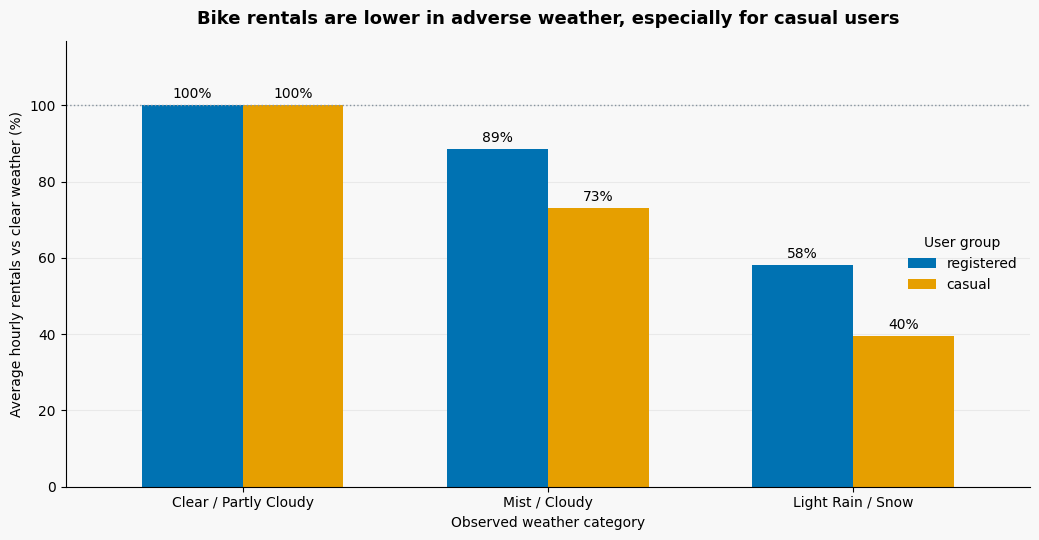

Number of observed hours in each weather category:


,hours
weathersit,
1,11413
2,4544
3,1419


Mean hourly rentals (counts):


,registered,casual
weathersit,,
1,164.3,40.5
2,145.6,29.6
3,95.5,16.1


Relative to clear weather (%):


,registered,casual
Clear / Partly Cloudy,100.0,100.0
Mist / Cloudy,88.6,73.0
Light Rain / Snow,58.1,39.6


In [1]:
# Meteo e noleggi

# Importiamo le librerie e definiamo i colori dei due utenti.
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
CASUAL = '#E69F00'
NEUTRAL = '#86939E'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo i dati orari già puliti.
hour=pd.read_csv('../data/processed/bike_hour_clean.csv')
Path('../output/figures').mkdir(parents=True,exist_ok=True)

# Confrontiamo le tre categorie meteo con abbastanza osservazioni.
data=hour.loc[hour['weathersit'].isin([1,2,3])].copy()

# Contiamo le ore osservate in ogni categoria.
counts=data.groupby('weathersit').size()

# Calcoliamo la media dei noleggi per tipo di utente.
avg=data.groupby('weathersit')[['registered','casual']].mean()

# Confrontiamo ogni media con il tempo sereno, fissato a 100%.
normalized=avg.div(avg.loc[1],axis='columns')*100
normalized.index=['Clear / Partly Cloudy','Mist / Cloudy','Light Rain / Snow']

# Disegniamo le barre con le percentuali visibili.
fig,ax=plt.subplots(figsize=(10.5,5.5))
normalized.plot(kind='bar',ax=ax,width=.66,
                color=[REGISTERED,CASUAL])
for bars in ax.containers:
    ax.bar_label(bars,fmt='%.0f%%',padding=3,fontsize=10)
ax.set_title('Bike rentals are lower in adverse weather, especially for casual users',
             fontsize=13,fontweight='bold',pad=12)
ax.set_ylabel('Average hourly rentals vs clear weather (%)')
ax.set_xlabel('Observed weather category')
ax.set_xticklabels(normalized.index,rotation=0)
ax.set_ylim(0,max(117,float(normalized.max().max())+15))
ax.axhline(100,color=NEUTRAL,linestyle=':',linewidth=1)
ax.legend(title='User group',frameon=False)
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig('../output/figures/RQ3_weather_comparison.png',dpi=200,bbox_inches='tight')
plt.show()

# Stampiamo i numeri utilizzati nel grafico.
print('Number of observed hours in each weather category:')
display(counts.to_frame('hours'))
print('Mean hourly rentals (counts):');display(avg.round(1))
print('Relative to clear weather (%):');display(normalized.round(1))